In [12]:
# Importações
import matplotlib.pyplot as plt
import SimpleITK as sitk
from pathlib import Path
import numpy as np
import cv2

In [13]:
# Definição dos caminhos dos arquivos de teste
t2w_path = Path("../src/data/raw/picai/10000/10000_1000000_t2w.mha")
mask_path = Path("../src/data/raw/picai_labels/anatomical_delineations/whole_gland/AI/Bosma22b/10000_1000000.nii.gz")

In [14]:
# Leitura das imagens de teste
t2w_img = sitk.ReadImage(str(t2w_path))
mask_img = sitk.ReadImage(str(mask_path))

In [15]:
# Conversão das imagens de teste para arrays NumPy
t2w = sitk.GetArrayFromImage(t2w_img)
mask = sitk.GetArrayFromImage(mask_img)

In [16]:
# Visualização de uma fatia central da imagem T2W e da máscara correspondente
slice_idx = t2w.shape[0] // 2

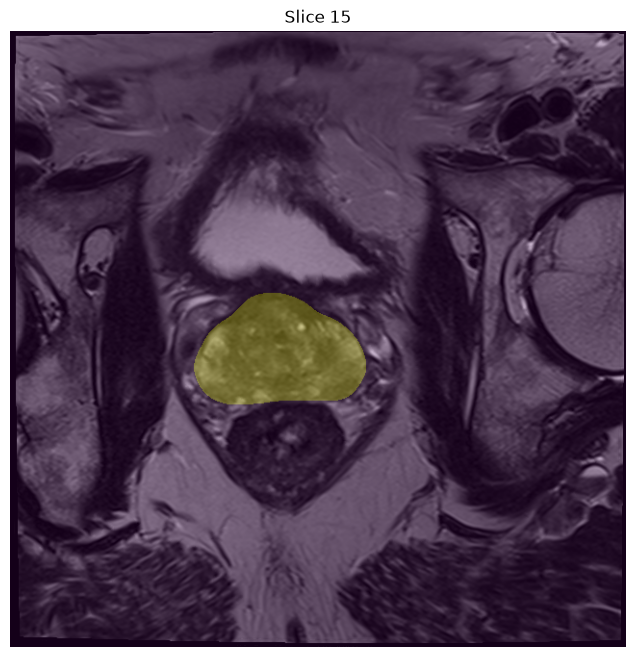

In [17]:
plt.figure(figsize=(8, 8))
plt.imshow(t2w[slice_idx], cmap="gray")
plt.imshow(mask[slice_idx], alpha=0.3)
plt.title(f"Slice {slice_idx}")
plt.axis("off")
plt.show()

In [18]:
slices_com_prostata = []

for i in range(mask.shape[0]):
    if np.any(mask[i] > 0):
        slices_com_prostata.append(i)

print("Slices com próstata:", slices_com_prostata)
print("Quantidade:", len(slices_com_prostata))

Slices com próstata: [8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Quantidade: 12


In [19]:
for i in slices_com_prostata:
    print("Slice:", i, "| Pixels da máscara:", np.sum(mask[i] > 0))

Slice: 8 | Pixels da máscara: 5311
Slice: 9 | Pixels da máscara: 6989
Slice: 10 | Pixels da máscara: 9864
Slice: 11 | Pixels da máscara: 12747
Slice: 12 | Pixels da máscara: 14815
Slice: 13 | Pixels da máscara: 16258
Slice: 14 | Pixels da máscara: 16616
Slice: 15 | Pixels da máscara: 15692
Slice: 16 | Pixels da máscara: 14241
Slice: 17 | Pixels da máscara: 12097
Slice: 18 | Pixels da máscara: 9377
Slice: 19 | Pixels da máscara: 2788


In [20]:
def select_sliced_with_context( mask, context=2):
    positive = [
        i for i in range(mask.shape[0])
        if np.any(mask[i] > 0)
    ]
    
    if not positive:
        return []
    
    first = positive[0]
    last = positive[-1] 
    
    begin = max(0, first - context)
    end = min(mask.shape[0] - 1, last + context)
    
    return list(range(begin, end + 1))

In [21]:
slices_selecionados = select_sliced_with_context(mask, context=2)

print("Slices selecionados:", slices_selecionados)
print("Quantidade total:", len(slices_selecionados))

Slices selecionados: [6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]
Quantidade total: 16


In [22]:
def t2w_normalize(slice_img):
    """
    Normalização z-score apenas na região não nula.
    """
    slice_img = slice_img.astype(np.float32)

    non_zero = slice_img[slice_img > 0]

    if len(non_zero) == 0:
        return slice_img

    mean = non_zero.mean()
    std = non_zero.std()

    if std == 0:
        return slice_img

    normalized = (slice_img - mean) / std

    return normalized


In [23]:
def resize_slice(image, mask, size=(256, 256)):
    image_resized = cv2.resize(
        image,
        size,
        interpolation=cv2.INTER_LINEAR
    )

    mask_resized = cv2.resize(
        mask.astype(np.uint8),
        size,
        interpolation=cv2.INTER_NEAREST
    )

    mask_resized = (mask_resized > 0).astype(np.uint8)

    return image_resized, mask_resized


In [24]:
slice_idx = 13

img_slice = t2w[slice_idx]
mask_slice = mask[slice_idx]

img_norm = t2w_normalize(img_slice)

img_resize, mask_resize = resize_slice(
    img_norm,
    mask_slice,
    size=(256, 256)
)

print("Imagem original:", img_slice.shape)
print("Máscara original:", mask_slice.shape)

print("Imagem processada:", img_resize.shape)
print("Máscara processada:", mask_resize.shape)

print("Valores únicos da máscara:", np.unique(mask_resize))

Imagem original: (640, 640)
Máscara original: (640, 640)
Imagem processada: (256, 256)
Máscara processada: (256, 256)
Valores únicos da máscara: [0 1]
